In [7]:
import numpy as np
from scipy.integrate import solve_bvp

def _vNtoQ_num_new(T, aQstar, aN, muQ):
    """
    Phase boundary velocity via half-line BVP compactification.

    Solves DQ * ∂_x^2 a - v * ∂_x a - R(a) = 0 on x ∈ [0, ∞),
    with a(0)=aQstar and a(∞)=0, plus the flux/slope condition at x=0:
        ∂_x a(0) = - v (aN - aQstar) / DQ.

    Compactify with s = exp(-x/x0), so x ∈ [0,∞) ↔ s ∈ (0,1].
    Unknown parameter v is solved internally by solve_bvp via p=[v].
    """

    if aN < aQstar:
        print("hit aN < aQstar, returning velocity = 0.0")
        return 0.0

    T = float(T)
    if T < 0.0:
        raise RuntimeError("negative temperature")
    if T == 0.0:
        raise RuntimeError("T==0 not supported: etaQ -> 0 makes the tail length diverge.")

    alpha_s = 0.3

    # --- microphysics (unchanged) ---
    g_s   = np.sqrt(4*np.pi*alpha_s)
    etaQ  = (9*np.pi**2 * T**2) / (muQ**2)
    tauQ  = 1.98e12 * ((300.0 / muQ)**5)

    qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h     = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    # Reaction term
    def R(a):
        a_safe = np.clip(a, -7e2, 7e2)
        return (a_safe**3 + etaQ * a_safe) / tauQ

    # Linear tail exponent in x near a=0:
    # DQ a_xx - v a_x - (etaQ/tauQ) a = 0
    # lambda_- < 0
    def lambda_minus(v):
        v = float(abs(v))
        disc = v*v + 4.0 * DQ * etaQ / tauQ
        return (v - np.sqrt(disc)) / (2.0 * DQ)

    # ------------------------------------------------------------------
    # Compactification: s = exp(-x/x0), so x = -x0 ln s.
    #
    # Then:
    #   ds/dx = -(1/x0) s
    #   d/dx = (ds/dx) d/ds = -(s/x0) d/ds
    #
    # Let y0(s)=a(s), y1(s)=∂_x a = p(s).
    #
    # We want an ODE in s:
    #   ∂_x a = p
    #   ∂_x p = (v p + R(a))/DQ
    #
    # Convert to s derivatives:
    #   da/ds = (da/dx) / (ds/dx) = p / (-(s/x0)) = -x0 * p / s
    #   dp/ds = (dp/dx) / (ds/dx) = ((v p + R)/DQ) / (-(s/x0)) = -x0*(v p + R)/(DQ*s)
    #
    # This has 1/s factors near s=0, but we never evaluate at s=0 exactly.
    # ------------------------------------------------------------------

    # Choose x0 (a scale for the mapping).
    # This is not a truncation length; it sets how quickly s runs to 0 with x.
    # A robust choice is to use the linear tail scale at an initial v guess.
    v_init = 1e-7
    lam0 = lambda_minus(v_init)
    # If lam0 is extremely small in magnitude, pick a conservative x0.
    # x0 ~ 1/|lam0| is a natural length scale for the tail.
    if np.isfinite(lam0) and abs(lam0) > 1e-18:
        x0 = float(1.0 / abs(lam0))
    else:
        x0 = 1e6  # fallback in natural units

    # Smallest s we include. This corresponds to x_max = -x0 ln(s_min).
    # This is unavoidable numerically; choose it based on floating point and tolerance.
    s_min = 1e-12
    s = np.linspace(s_min, 1.0, 800)

    def ode(s, y, p):
        v = float(abs(p[0]))
        a = y[0]
        px = y[1]  # px = ∂_x a
        da_ds  = -x0 * px / s
        dpx_ds = -x0 * (v * px + R(a)) / (DQ * s)
        return np.vstack((da_ds, dpx_ds))

    # Boundary conditions:
    # At s=1 (x=0): a=aQstar, and px = ∂_x a = - v(aN-aQstar)/DQ
    # At s=s_min (x ~ ∞): enforce decaying-mode tail: px = lambda_-(v) * a
    def bc(ya, yb, p):
        # NOTE: ya corresponds to s_min (x large), yb corresponds to s=1 (x=0)
        v = float(abs(p[0]))
        return np.array([
            ya[1] - lambda_minus(v) * ya[0],             # tail at infinity
            yb[0] - aQstar,                              # a(0)=aQstar
            yb[1] + v * (aN - aQstar) / DQ,              # ∂_x a(0) condition
        ], dtype=float)

    # Initial guess: use linear tail everywhere in s
    # a(x) ~ aQstar exp(lam0 x), with x=-x0 ln s => a(s) ~ aQstar * s^{-lam0 x0}
    # Because lam0<0, -lam0 x0 ~ +1 ideally, so a ~ aQstar * s^{k} with k>0 decaying as s->0
    k = float(max(0.5, min(5.0, -lam0 * x0 if np.isfinite(lam0) else 1.0)))
    a_guess = aQstar * (s ** k)
    # px = ∂_x a = d a/dx = -(s/x0) d a/ds
    da_ds_guess = aQstar * k * (s ** (k - 1.0))
    px_guess = -(s / x0) * da_ds_guess
    y_init = np.vstack((a_guess, px_guess))

    sol = solve_bvp(
        ode, bc, s, y_init, p=np.array([v_init], dtype=float),
        tol=1e-6, max_nodes=200000, verbose=0
    )

    # One controlled retry: adjust x0 and s_min if needed (common at very low T)
    if sol.status != 0 or not sol.success or not np.isfinite(sol.p[0]) or sol.p[0] <= 0.0:
        v_try = float(abs(sol.p[0])) if (sol.p is not None and np.isfinite(sol.p[0])) else 1e-6
        lam_try = lambda_minus(v_try)
        if np.isfinite(lam_try) and abs(lam_try) > 1e-20:
            x0 = float(2.0 / abs(lam_try))  # loosen mapping a bit
        s_min = 1e-14
        s = np.linspace(s_min, 1.0, 1200)

        k = float(max(0.5, min(5.0, -lam_try * x0 if np.isfinite(lam_try) else 1.0)))
        a_guess = aQstar * (s ** k)
        da_ds_guess = aQstar * k * (s ** (k - 1.0))
        px_guess = -(s / x0) * da_ds_guess
        y_init = np.vstack((a_guess, px_guess))

        sol = solve_bvp(
            ode, bc, s, y_init, p=np.array([v_try], dtype=float),
            tol=1e-6, max_nodes=400000, verbose=0
        )

    if sol.status != 0 or not sol.success:
        raise RuntimeError(f"solve_bvp failed: status={sol.status}, message={sol.message}")

    v_nat = float(abs(sol.p[0]))  # natural units (c=1)
    return v_nat * 3e8

In [10]:
from RMFsolver.phase_velocity import _vNtoQ_formula, _vNtoQ_num

T = 0.1
aQstar = 0.5
aN = 0.8
muQ = 300

print(_vNtoQ_formula(T, aQstar, aN, muQ))
print(_vNtoQ_num_new(T, aQstar, aN, muQ))
print(_vNtoQ_num(T, aQstar, aN, muQ))

2720.380703982652


RuntimeError: solve_bvp failed: status=1, message=The maximum number of mesh nodes is exceeded.

### Choice of the physical truncation length $L$

We solve the boundary-value problem on the half line
$$
x \in [0,\infty), \qquad
D_Q\,\partial_x^2 a - v\,\partial_x a - R(a) = 0,
$$
with
$$
a(0)=a_Q^\star, \qquad a(\infty)=0.
$$

Numerically, the half line must be replaced by a finite interval
$$
x \in [0,L],
$$
together with a boundary condition at $x=L$ that correctly represents the
asymptotic decay as $x\to\infty$.

---

### Tail decay scale

For small $a$, the reaction term linearizes as
$$
R(a) \simeq \frac{\eta_Q}{\tau_Q} a .
$$
The asymptotic equation becomes
$$
D_Q\,\partial_x^2 a - v\,\partial_x a - \frac{\eta_Q}{\tau_Q} a = 0 .
$$

Its characteristic exponents are
$$
\lambda_{\pm}
= \frac{v \pm \sqrt{v^2 + 4D_Q\,\eta_Q/\tau_Q}}{2D_Q},
$$
with
$$
\lambda_- < 0 .
$$

Therefore, the physically admissible tail behaves as
$$
a(x) \sim C\,e^{\lambda_- x} \quad (x\to\infty).
$$

The characteristic decay length is
$$
\ell_{\text{tail}} = \frac{1}{|\lambda_-|}.
$$

---

### Practical choice of $L$

To ensure that the solution is already deep in the asymptotic regime at $x=L$,
we choose
$$
\boxed{
L = \frac{N}{|\lambda_-|}
}
$$
with
$$
N \sim 20\text{--}30 .
$$

This guarantees
$$
\frac{a(L)}{a(0)} \sim e^{-N} \ll 1,
$$
while keeping the domain as short as possible.

---

### Boundary condition at $x=L$

Instead of imposing $a(L)=0$, we impose the asymptotically correct Robin
condition
$$
\boxed{
\partial_x a(L) = \lambda_-\, a(L),
}
$$
which exactly enforces that only the decaying mode is present.

---

### Typical magnitude of $L$ (in km)

Lengths in the code are measured in natural units (MeV$^{-1}$).
The conversion to SI units is
$$
1~\text{MeV}^{-1} = \hbar c \simeq 1.97327\times 10^{-13}\,\text{m}
= 1.97327\times 10^{-16}\,\text{km}.
$$

Hence,
$$
L_{\text{km}} \simeq
1.97\times 10^{-16}\, L_{\text{(MeV}^{-1})}.
$$

Examples:
- $L = 10^{15}\,\text{MeV}^{-1} \;\Rightarrow\; L \approx 0.20\,\text{km}$,
- $L = 10^{16}\,\text{MeV}^{-1} \;\Rightarrow\; L \approx 2.0\,\text{km}$,
- $L = 5\times 10^{16}\,\text{MeV}^{-1} \;\Rightarrow\; L \approx 10\,\text{km}$.

At low temperature, $|\lambda_-|$ becomes small, so $L$ can naturally reach
kilometer scales. This is a physical consequence of the long tail, not a
numerical artifact.

In [72]:
import numpy as np
from scipy.integrate import solve_bvp

def _vNtoQ_num_new2(T, aQstar, aN, muQ):
    """
    Phase boundary velocity using direct x-space truncation and Robin tail BC.
    No rescaling, no compactification.
    """

    if aN < aQstar:
        return 0.0

    T = float(T)
    if T <= 0.0:
        raise RuntimeError("T must be positive")

    alpha_s = 0.3

    # --- microphysics ---
    g_s   = np.sqrt(4*np.pi*alpha_s)
    etaQ  = (9*np.pi**2 * T**2) / (muQ**2)
    tauQ  = 1.98e12 * ((300.0 / muQ)**5)

    qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h     = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    def R(a):
        a_safe = np.clip(a, -7e2, 7e2)
        return (a_safe**3 + etaQ * a_safe) / tauQ

    # Decaying eigenvalue
    def lambda_minus(v):
        disc = v*v + 4.0 * DQ * etaQ / tauQ
        return (v - np.sqrt(disc)) / (2.0 * DQ)

    # Initial guess for v
    v_init = 1e-7

    # Choose truncation length L = N / |lambda_-|
    Ntail = 50.0
    lam0 = lambda_minus(v_init)
    if not np.isfinite(lam0) or lam0 >= 0.0:
        raise RuntimeError("Invalid initial lambda_-")
    L = Ntail / abs(lam0)

    # Build x grid
    x = np.linspace(0.0, L, 800)

    # ODE system
    # y[0] = a, y[1] = ∂_x a
    def ode(x, y, p):
        v = abs(p[0])
        a = y[0]
        px = y[1]
        return np.vstack((
            px,
            (v * px + R(a)) / DQ
        ))

    # Boundary conditions
    def bc(ya, yb, p):
        v = abs(p[0])
        lam = lambda_minus(v)
        return np.array([
            ya[0] - aQstar,                          # a(0)=aQstar
            ya[1] + v * (aN - aQstar) / DQ,          # ∂_x a(0)
            yb[1] - lam * yb[0],                     # tail BC at x=L
        ])

    # Initial guess for solution
    a_guess = aQstar * np.exp(lam0 * x)
    px_guess = lam0 * a_guess
    y_init = np.vstack((a_guess, px_guess))

    sol = solve_bvp(
        ode, bc, x, y_init, p=np.array([v_init]),
        tol=1e-6, max_nodes=200000
    )

    if not sol.success:
        raise RuntimeError(f"solve_bvp failed: {sol.message}")

    v_nat = abs(sol.p[0])   # natural units (c=1)
    return v_nat * 3e8, L * 1.97327e-16      # convert

In [73]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def integrate_ivp_and_plot_a(
    v_si,                 # velocity in m/s
    L_ivp,                # IVP integration length (MeV^-1) — NOT the BVP truncation
    T,                    # temperature (MeV)
    aQstar,
    aN,
    muQ,
    rtol=1e-8,
    atol=1e-10
):
    """
    Integrate the IVP for a given v on x ∈ [0, L_ivp] and plot a(x).

    Governing equations:
        ∂_x a = p
        ∂_x p = (v p + R(a)) / DQ

    Initial conditions:
        a(0) = aQstar
        ∂_x a(0) = - v (aN - aQstar) / DQ
    """

    # ------------------------------------------------
    # Convert velocity to natural units (c = 1)
    # ------------------------------------------------
    v = v_si / 3e8

    # ------------------------------------------------
    # Microphysics (must match BVP solver)
    # ------------------------------------------------
    alpha_s = 0.3
    g_s   = np.sqrt(4*np.pi*alpha_s)
    etaQ  = (9*np.pi**2 * T**2) / (muQ**2)
    tauQ  = 1.98e12 * ((300.0 / muQ)**5)

    qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h     = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    def R(a):
        return (a**3 + etaQ * a) / tauQ

    # ------------------------------------------------
    # ODE system (IVP)
    # ------------------------------------------------
    def ode(x, y):
        a, p = y
        return [
            p,
            (v * p + R(a)) / DQ
        ]

    # ------------------------------------------------
    # Initial conditions at x = 0
    # ------------------------------------------------
    a0 = aQstar
    p0 = -v * (aN - aQstar) / DQ

    # ------------------------------------------------
    # Solve IVP
    # ------------------------------------------------
    sol = solve_ivp(
        ode,
        (0.0, L_ivp),
        [a0, p0],
        rtol=rtol,
        atol=atol
    )

    # ------------------------------------------------
    # Plot a(x)
    # ------------------------------------------------
    plt.figure()
    plt.plot(sol.t, sol.y[0])
    plt.xlabel(r"$x\;(\mathrm{MeV}^{-1})$")
    plt.ylabel(r"$a(x)$")
    plt.title(
        rf"$a(x)$ IVP,  $T={T}$ MeV,  $v={v_si:.2f}$ m/s"
    )
    plt.show()

    return None

In [58]:
from RMFsolver.phase_velocity import _vNtoQ_formula, _vNtoQ_num

T = 5
aQstar = 0.5
aN = 0.8
muQ = 300

print(_vNtoQ_formula(T, aQstar, aN, muQ))
print(_vNtoQ_num_new2(T, aQstar, aN, muQ))
#print(_vNtoQ_num(T, aQstar, aN, muQ))

101.69527630095203
(np.float64(122.82007198376584), np.float64(1.534582373811167e-07))


777.6849462117028


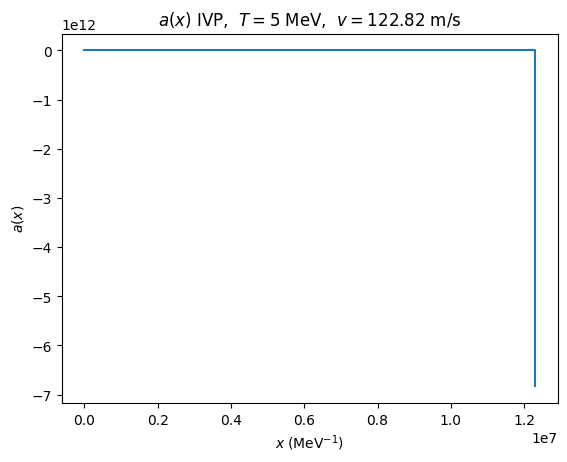

In [75]:
vv, LL = _vNtoQ_num_new2(T, aQstar, aN, muQ)

print((LL/1.97327e-16)/1e6)

integrate_ivp_and_plot_a(
    v_si = vv,                 # velocity in m/s
    L_ivp = LL/1.97327e-16,                    # integration length (MeV^-1)
    T = 5,                    # temperature (MeV)
    aQstar = 0.5,
    aN = 0.8,
    muQ = 300,
    rtol=1e-8,
    atol=1e-10
)

## Adaptive choice of the truncation length $L$: tail-length + linear-tail validity

We solve the half-line problem by truncating to $x\in[0,L]$ and imposing the asymptotically correct Robin boundary condition at $x=L$:
$$
\partial_x a(L)=\lambda_-(v)\,a(L),
\qquad
\lambda_-(v)=\frac{v-\sqrt{v^2+4D_Q\,\eta_Q/\tau_Q}}{2D_Q}<0.
$$

This Robin condition is derived from the *linearized* tail equation, which assumes
$$
R(a)=\frac{a^3+\eta_Q a}{\tau_Q}\approx \frac{\eta_Q a}{\tau_Q}.
$$
That approximation requires the cubic to be negligible compared to the linear term:
$$
|a|^3 \ll \eta_Q |a| \quad\Longleftrightarrow\quad a^2 \ll \eta_Q.
$$

### Two criteria for choosing $L$

1) **Tail-length criterion (geometric decay):**
$$
L_{\text{tail}} = \frac{N_{\text{tail}}}{|\lambda_-(v)|},
$$
so that the decaying mode suppresses the amplitude by $\sim e^{-N_{\text{tail}}}$.

2) **Linear-tail validity criterion (physics):**
We require the solution at the boundary to lie inside the linear regime:
$$
a(L)^2 \le \frac{\eta_Q}{\mathcal{C}},
$$
where $\mathcal{C}\gg 1$ is a safety factor (e.g. $\mathcal{C}=10^3$ gives $a(L)^2/\eta_Q\le10^{-3}$).

### Adaptive algorithm

Because $v$ and $a(L)$ are not known a priori, we iterate:

- Start with an initial guess $v_{\rm init}$, compute $L=L_{\text{tail}}(v_{\rm init})$.
- Solve the BVP on $[0,L]$ using `solve_bvp` with $v$ as an unknown parameter.
- Evaluate $a(L)$ from the solution.
- If $a(L)^2 > \eta_Q/\mathcal{C}$, increase $L$ (e.g. multiply by 2) and re-solve, using the previous solution as the initial guess.
- Stop when both criteria are satisfied, and return $v$ (m/s) and $L$ (km).

### Unit conversion

The solver uses natural-length units (MeV$^{-1}$). Convert to km via:
$$
L_{\rm km} = L_{\rm (MeV^{-1})}\times (\hbar c) \simeq L\times 1.97327\times 10^{-16}\ {\rm km}.
$$

In [86]:
import numpy as np
from scipy.integrate import solve_bvp

def _vNtoQ_num_new3(T, aQstar, aN, muQ,
              Ntail=50.0,
              C_lin=10,          # require a(L)^2 <= etaQ / C_lin
              L_growth=2.0,       # factor to grow L if linear regime not reached
              max_iter=8,
              tol=1e-6,
              max_nodes=300000):
    """
    Solve for v using a truncated-domain BVP on x ∈ [0, L] with:
      a(0)=aQstar,
      ∂_x a(0) = - v (aN-aQstar)/DQ,
      ∂_x a(L) = λ_-(v) a(L)   (Robin tail BC).

    L is chosen adaptively to satisfy BOTH:
      (i)  L >= Ntail/|λ_-|,
      (ii) a(L)^2 <= etaQ / C_lin  (ensures etaQ*a >> a^3 at boundary).

    Returns:
      (v_si, L_km)
    """

    if aN < aQstar:
        return 0.0, 0.0

    T = float(T)
    if T <= 0.0:
        raise RuntimeError("T must be positive")

    alpha_s = 0.3

    # --- microphysics (unchanged) ---
    g_s   = np.sqrt(4*np.pi*alpha_s)
    etaQ  = (9*np.pi**2 * T**2) / (muQ**2)
    tauQ  = 1.98e12 * ((300.0 / muQ)**5)

    qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h     = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    def R(a):
        a_safe = np.clip(a, -7e2, 7e2)
        return (a_safe**3 + etaQ * a_safe) / tauQ

    def lambda_minus(v):
        v = float(abs(v))
        disc = v*v + 4.0 * DQ * etaQ / tauQ
        return (v - np.sqrt(disc)) / (2.0 * DQ)  # < 0

    # --- BVP pieces with unknown parameter p[0]=v ---
    def ode(x, y, p):
        v = float(abs(p[0]))
        a = y[0]
        px = y[1]  # px = ∂_x a
        return np.vstack((px, (v * px + R(a)) / DQ))

    def bc(ya, yb, p):
        v = float(abs(p[0]))
        lam = lambda_minus(v)
        return np.array([
            ya[0] - aQstar,                        # a(0)=aQstar
            ya[1] + v * (aN - aQstar) / DQ,        # ∂_x a(0)
            yb[1] - lam * yb[0],                   # ∂_x a(L)=λ_- a(L)
        ], dtype=float)

    # --- initial v guess (natural units) ---
    v_init = 1e-7

    # --- initial L from tail-length criterion using v_init ---
    lam0 = lambda_minus(v_init)
    if not np.isfinite(lam0) or lam0 >= 0.0:
        raise RuntimeError("Invalid initial lambda_-; check parameters.")
    L = float(Ntail / abs(lam0))

    # Build an initial mesh and guess
    x = np.linspace(0.0, L, 800)
    a_guess = aQstar * np.exp(lam0 * x)
    px_guess = lam0 * a_guess
    y_init = np.vstack((a_guess, px_guess))
    p_init = np.array([v_init], dtype=float)

    prev_sol = None

    for it in range(max_iter):
        sol = solve_bvp(
            ode, bc, x, y_init, p=p_init,
            tol=tol, max_nodes=max_nodes, verbose=0
        )

        if not sol.success or not np.isfinite(sol.p[0]) or sol.p[0] <= 0.0:
            # If it fails, try a more conservative L and a slightly different seed
            L *= L_growth
            x = np.linspace(0.0, L, 1200)
            # reset guess with the same exponential form
            lam_try = lambda_minus(float(abs(p_init[0])))
            a_guess = aQstar * np.exp(lam_try * x)
            px_guess = lam_try * a_guess
            y_init = np.vstack((a_guess, px_guess))
            p_init = np.array([max(1e-9, float(abs(p_init[0]))),], dtype=float)
            prev_sol = None
            continue

        v_sol = float(abs(sol.p[0]))
        lam_sol = lambda_minus(v_sol)

        # Enforce tail-length criterion with the *solved* v:
        L_tail = float(Ntail / max(abs(lam_sol), 1e-300))

        # Evaluate a(L) from solution (right boundary)
        aL = float(sol.y[0, -1])
        # Linear-regime criterion: a(L)^2 <= etaQ / C_lin
        lin_ok = (aL*aL <= etaQ / C_lin)

        # Tail-length criterion: current L >= L_tail
        tail_ok = (L >= L_tail)

        if lin_ok and tail_ok:
            # done
            v_si = v_sol * 3e8
            L_km = L * 1.97327e-16
            return v_si, L_km

        # Otherwise, increase L to satisfy whichever is more demanding:
        # - ensure at least L_tail,
        # - and if linear regime not met, grow L further.
        newL = max(L, L_tail)
        if not lin_ok:
            newL *= L_growth

        # Prepare a new mesh and use the previous solution as initial guess by evaluation
        L = float(newL)
        x_new = np.linspace(0.0, L, max(800, len(x)))
        y_new = sol.sol(x_new)   # shape (2, n)
        y_init = y_new
        p_init = np.array([v_sol], dtype=float)
        x = x_new
        prev_sol = sol

    raise RuntimeError(
        "Adaptive BVP did not converge within max_iter. "
        "Try increasing max_iter, max_nodes, or relaxing C_lin."
    )

In [91]:
from RMFsolver.phase_velocity import _vNtoQ_formula, _vNtoQ_num

T = 0.5
aQstar = 0.5
aN = 0.8
muQ = 300

print(_vNtoQ_formula(T, aQstar, aN, muQ))
print(_vNtoQ_num_new3(T, aQstar, aN, muQ))
print(_vNtoQ_num(T, aQstar, aN, muQ))

688.6308528413022


RuntimeError: Adaptive BVP did not converge within max_iter. Try increasing max_iter, max_nodes, or relaxing C_lin.

1804.8525091218296


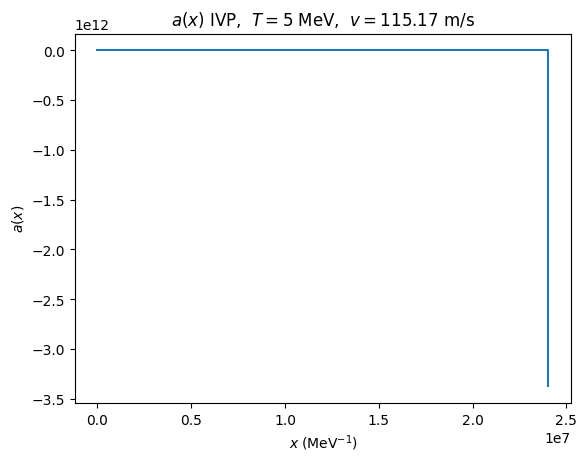

In [90]:
vv, LL = _vNtoQ_num_new3(T, aQstar, aN, muQ)

print((LL/1.97327e-16)/1e6)

integrate_ivp_and_plot_a(
    v_si = vv,                 # velocity in m/s
    L_ivp = LL/1.97327e-16,                    # integration length (MeV^-1)
    T = 5,                    # temperature (MeV)
    aQstar = 0.5,
    aN = 0.8,
    muQ = 300,
    rtol=1e-8,
    atol=1e-10
)

## Fast adaptive choice of truncation length L for the Robin BVP (no slow multi-resolve loop)

We solve, on a truncated domain x ∈ [0, L],

$$
D_Q \,\partial_x^2 a - v\,\partial_x a - R(a) = 0,
\qquad
R(a)=\frac{a^3+\eta_Q a}{\tau_Q},
$$

with unknown parameter v > 0 determined by the three boundary conditions

$$
a(0)=a_Q^\star,
\qquad
\partial_x a(0) = -\frac{v}{D_Q}(a_N-a_Q^\star),
\qquad
\partial_x a(L) = \lambda_-(v)\,a(L).
$$

Here the decaying tail exponent λ_-(v) is from the linearized tail near a ≈ 0:

$$
\lambda_-(v)=\frac{v-\sqrt{v^2+4D_Q\,\eta_Q/\tau_Q}}{2D_Q} < 0.
$$

### Why L needs to be chosen carefully

The Robin boundary condition is derived by linearizing the reaction term in the tail:

$$
R(a)=\frac{a^3+\eta_Q a}{\tau_Q} \approx \frac{\eta_Q a}{\tau_Q}.
$$

This approximation is valid when the linear term dominates the cubic term:

$$
\eta_Q |a| \gg |a|^3
\quad \Longleftrightarrow \quad
a^2 \ll \eta_Q.
$$

If this is not true at x=L, then enforcing the linearized exponent λ_- at x=L can bias the solution.

### Two a-priori criteria for L

We choose L as the maximum of two lengths computed from an initial guess for v:

1) Tail-length criterion (geometric decay depth):

$$
L_{\rm tail} = \frac{N_{\rm tail}}{|\lambda_-|}.
$$

2) Linear-tail amplitude criterion (ensure a(L) is in the linear regime):

Choose a target tail amplitude

$$
a_{\rm lin} = \sqrt{\frac{\eta_Q}{C_{\rm lin}}},
$$

which enforces

$$
a(L)^2 \le \frac{\eta_Q}{C_{\rm lin}}.
$$

Assuming an exponential tail $a(x) \sim a_Q^\star e^{\lambda_- x}$, this implies

$$
L_{\rm lin} = \frac{1}{|\lambda_-|}\ln\!\left(\frac{a_Q^\star}{a_{\rm lin}}\right)
\quad \text{(and set } L_{\rm lin}=0 \text{ if } a_Q^\star \le a_{\rm lin}\text{)}.
$$

Final choice:

$$
L = \max(L_{\rm tail}, L_{\rm lin}).
$$

### Why this is fast

- Compute L once from an initial v guess.
- Solve the BVP once using solve_bvp with v as an unknown parameter.
- Optionally refine once: recompute L using the solved v and re-solve a second time only if L changes significantly.

No slow outer loop that repeatedly grows L and re-solves many times.

### Unit conversion

The solver uses x in MeV^{-1}. Convert to km via

$$
1~{\rm MeV}^{-1} = \hbar c \simeq 1.97327\times 10^{-16}~{\rm km},
$$

so

$$
L_{\rm km} = L \times 1.97327\times 10^{-16}.
$$

In [92]:
import numpy as np
from scipy.integrate import solve_bvp

def _vNtoQ_num_new4(
    T, aQstar, aN, muQ,
    Ntail=50.0,
    C_lin=1e3,            # demand a(L)^2 <= etaQ/C_lin (larger = stricter)
    refine_once=True,     # do at most one L-update using solved v
    v_init=1e-7,          # initial guess for v in natural units (c=1)
    tol=1e-6,
    max_nodes=300000,
    n_mesh=900,
    L_change_trigger=0.2  # redo if |L2-L|/L > this
):
    """
    Fast truncated Robin BVP solver for v.

    Solves on x ∈ [0, L]:
      y0 = a, y1 = ∂_x a
      ∂_x a = y1
      ∂_x y1 = (v y1 + R(a)) / DQ

    BCs:
      a(0) = aQstar
      ∂_x a(0) = - v (aN-aQstar)/DQ
      ∂_x a(L) = λ_-(v) a(L)

    L is chosen as max(L_tail, L_lin) computed from λ_-(v_guess).
    Returns (v_si, L_km).
    """

    if aN < aQstar:
        return 0.0, 0.0

    T = float(T)
    if T <= 0.0:
        raise RuntimeError("T must be positive")

    alpha_s = 0.3

    # --- microphysics ---
    g_s   = np.sqrt(4*np.pi*alpha_s)
    etaQ  = (9*np.pi**2 * T**2) / (muQ**2)
    tauQ  = 1.98e12 * ((300.0 / muQ)**5)

    qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h     = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    def R(a):
        a_safe = np.clip(a, -7e2, 7e2)
        return (a_safe**3 + etaQ * a_safe) / tauQ

    def lambda_minus(v):
        v = float(abs(v))
        disc = v*v + 4.0 * DQ * etaQ / tauQ
        return (v - np.sqrt(disc)) / (2.0 * DQ)  # < 0

    def pick_L(v_guess):
        lam = lambda_minus(v_guess)
        if not np.isfinite(lam) or lam >= 0.0:
            raise RuntimeError("Bad lambda_- from v_guess; check parameters.")

        L_tail = float(Ntail / abs(lam))

        # amplitude target to ensure etaQ*a >> a^3 at x=L
        a_lin = np.sqrt(max(etaQ / C_lin, 1e-300))

        if aQstar <= a_lin:
            L_lin = 0.0
        else:
            L_lin = float((1.0 / abs(lam)) * np.log(aQstar / a_lin))

        return float(max(L_tail, L_lin)), float(lam)

    # --- BVP with unknown parameter p[0]=v ---
    def ode(x, y, p):
        v = float(abs(p[0]))
        a = y[0]
        px = y[1]
        return np.vstack((px, (v * px + R(a)) / DQ))

    def bc(ya, yb, p):
        v = float(abs(p[0]))
        lam = lambda_minus(v)
        return np.array([
            ya[0] - aQstar,
            ya[1] + v * (aN - aQstar) / DQ,
            yb[1] - lam * yb[0],
        ], dtype=float)

    # -----------------------
    # Pass #1: pick L from v_init and solve
    # -----------------------
    L, lam0 = pick_L(v_init)

    x = np.linspace(0.0, L, int(n_mesh))
    a_guess = aQstar * np.exp(lam0 * x)
    px_guess = lam0 * a_guess
    y_init = np.vstack((a_guess, px_guess))
    p_init = np.array([float(v_init)], dtype=float)

    sol = solve_bvp(
        ode, bc, x, y_init, p=p_init,
        tol=tol, max_nodes=max_nodes, verbose=0
    )
    if (not sol.success) or (not np.isfinite(sol.p[0])) or (sol.p[0] <= 0.0):
        raise RuntimeError(f"solve_bvp failed (pass #1): {sol.message}")

    v_sol = float(abs(sol.p[0]))

    # -----------------------
    # Optional pass #2: recompute L from v_sol and re-solve if L changes a lot
    # -----------------------
    if refine_once:
        L2, _ = pick_L(v_sol)
        if abs(L2 - L) / max(L, 1e-300) > float(L_change_trigger):
            x2 = np.linspace(0.0, L2, max(int(n_mesh), len(x)))
            y2 = sol.sol(x2)
            sol2 = solve_bvp(
                ode, bc, x2, y2, p=np.array([v_sol], dtype=float),
                tol=tol, max_nodes=max_nodes, verbose=0
            )
            if sol2.success and np.isfinite(sol2.p[0]) and sol2.p[0] > 0.0:
                sol = sol2
                v_sol = float(abs(sol.p[0]))
                L = float(L2)
            # else keep pass #1 result silently

    v_si = v_sol * 3e8
    L_km = float(L) * 1.97327e-16
    return v_si, L_km

In [128]:
from RMFsolver.phase_velocity import _vNtoQ_formula, _vNtoQ_num

T = 0.01
aQstar = 0.5
aN = 0.8
muQ = 300

print(_vNtoQ_formula(T, aQstar, aN, muQ))
print(_vNtoQ_num_new4(T, aQstar, aN, muQ))
#print(_vNtoQ_num_new2(T, aQstar, aN, muQ))
#print(_vNtoQ_num(T, aQstar, aN, muQ))

19038.660055694596
(8739.06598863469, 0.02464618882736419)


In [134]:
vv, LL = _vNtoQ_num_new4(T, aQstar, aN, muQ)

print((LL/1.97327e-16)/1e6, vv)

124900235.78812931 8739.06598863469


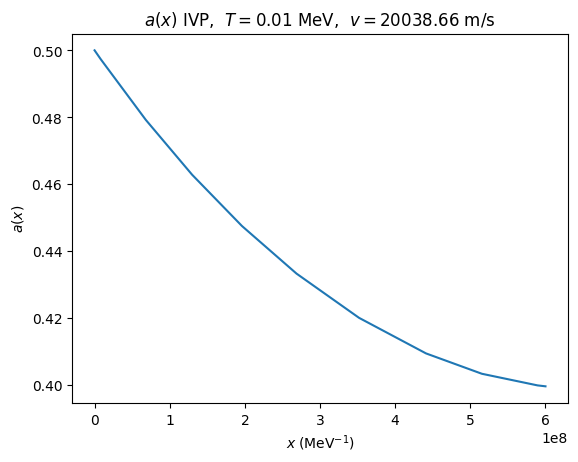

In [141]:
integrate_ivp_and_plot_a(
    v_si = 20038.660055694596,                 # velocity in m/s
    L_ivp = 6e8,                    # integration length (MeV^-1)
    T = 0.01,                    # temperature (MeV)
    aQstar = 0.5,
    aN = 0.8,
    muQ = 300,
    rtol=1e-8,
    atol=1e-10
)

* try plug in $z_0 = 10m$ and see
* plot the $a_{Q^*}^4 = 2\eta_Qa_{Q^*}^2$ line
* think independently
* look at Furusawa and think about heat conduction/entropy production and think if it's safe to assume uniform temperature. 

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from tqdm import tqdm
from scipy.interpolate import interp1d
from scipy.optimize import fsolve

from RMFsolver.phase_velocity import Get_aQstar_etaQ, Get_aQstar_etaQ0

n0 = 0.16 * const.MeV_fm**3
m_s = 0
NM_type = "PNM"
Deln, T = 0.3247118308907273, 32.05541858049335

aQs, etaQ = Get_aQstar_etaQ(T, 3*n0, Deln*n0, 0, para.paraQMCRMF3, "PNM")
aQs0, etaQ0 = Get_aQstar_etaQ0(T, 3*n0, Deln*n0, 0, para.paraQMCRMF3, "PNM")

aQs**4 - aQs**2 * 2*etaQ, aQs0**4 - aQs0**2 * 2*etaQ0

(np.float64(-0.16449889408387058), np.float64(-0.1749035074993911))

In [5]:
aQs**2 - 2*etaQ, aQs0**2 - 2*etaQ0, aQs**2

(np.float64(-0.9854838093675379),
 np.float64(-1.1417259247744889),
 np.float64(0.16692196515074398))